# 05 - Comparatie temporala si antrenare finala pe toate imaginile

Punct de plecare: full_train cu0.6968 Kaggle. Pasii acestui notebook: (1) o singura antrenare cu holdout compara raw, EMA si media ponderilor tarzii; (2) se fixeaza politica; (3) doua retele NOI sunt antrenate pe toate50k; (4) submission automat. **Fara Optuna.**

GPU T4x2 recomandat. Buget global700minute (11h40), cu maximum220 pentru comparatie si465+15 protejate pentru antrenarea finala/export. 

## 1. Antrenarea DivideMix de baza

Doua PreActResNet18 independente, warmup30, peer-GMM si MixMatch. 

### Imports and configuration

In [1]:
from dataclasses import asdict, dataclass
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from contextlib import nullcontext
import copy
import hashlib
import json
import math
import pickle
import random
import tempfile
import time
import uuid

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from sklearn.mixture import GaussianMixture


@dataclass
class Config:
    experiment_name: str = '05_dividemix_pair_budget170'
    data_root: str = (
        '/kaggle/input/competitions/dl-gen-ai-2026-fii-competition-3/'
        'fii-atnn-2024-project-noisy-cifar-100'
    )
    output_dir: str = '/kaggle/working'
    seed: int = 42
    epochs: int = 300
    warmup_epochs: int = 30
    batch_size: int = 64
    workers: int = 2
    validation_fraction: float = 0.1
    learning_rate: float = 0.02
    weight_decay: float = 5e-4
    mixup_alpha: float = 4.0
    temperature: float = 0.5
    clean_probability_threshold: float = 0.5
    unsupervised_weight: float = 25.0
    unsupervised_ramp_epochs: int = 16
    class_balance_weight: float = 1.0
    max_run_minutes: float = 170.0
    finalization_reserve_minutes: float = 15.0
    calibration_epochs: int = 3
    checkpoint_candidates: int = 3
    train_metrics_every: int = 5
    adaptive_epoch_plan: bool = True
    lr_drop_epoch: int = 0


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def model_fingerprint(model):
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        digest.update(name.encode())
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def cpu_state(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def run_deadlines(config):
    if not hasattr(config, '_run_started'):
        config._run_started = time.perf_counter()
    total = config._run_started + 60 * config.max_run_minutes
    return total - 60 * config.finalization_reserve_minutes, total


def plan_epochs(config, completed, mean_epoch_seconds, now=None):
    """Calibrate using robust rounds, not the cheaper warmup rounds."""
    deadline, _ = run_deadlines(config)
    now = time.perf_counter() if now is None else now
    remaining = max(0., deadline - now)
    extra = int(remaining // max(1e-6, 1.10 * mean_epoch_seconds))
    return min(config.epochs, completed + extra)


def training_devices():
    count = torch.cuda.device_count() if torch.cuda.is_available() else 0
    if count >= 2:
        return [torch.device('cuda:0'), torch.device('cuda:1')]
    device = torch.device('cuda:0' if count else 'cpu')
    return [device, device]


### Training data and two CIFAR networks

In [2]:
def validate_submission(frame, expected_ids):
    if list(frame.columns) != ['ID', 'target']:
        raise ValueError('The CSV must contain exactly ID,target, without an index column.')
    if frame.empty or len(frame) != len(expected_ids):
        raise ValueError('The submission must have one row per inference image.')
    if frame.isna().any().any():
        raise ValueError('Submission contains missing values.')
    if not all(pd.api.types.is_integer_dtype(frame[column]) for column in frame):
        raise ValueError('IDs and predicted classes must be integers.')
    if not frame.ID.is_unique or not np.array_equal(frame.ID.to_numpy(), expected_ids):
        raise ValueError('Submission IDs do not match the original image order.')
    if not frame.target.between(0, 99).all():
        raise ValueError('Predicted classes must be in [0,99].')


def check_inputs(config):
    run_deadlines(config)
    for name in ('epochs', 'batch_size', 'unsupervised_ramp_epochs', 'calibration_epochs',
                 'checkpoint_candidates', 'train_metrics_every'):
        if type(getattr(config, name)) is not int or getattr(config, name) < 1:
            raise ValueError(f'{name} must be a positive integer.')
    if type(config.workers) is not int or config.workers < 0:
        raise ValueError('workers must be a nonnegative integer.')
    if type(config.warmup_epochs) is not int or not 0 <= config.warmup_epochs <= config.epochs:
        raise ValueError('warmup_epochs must be between zero and epochs.')
    if type(config.lr_drop_epoch) is not int or not 0 <= config.lr_drop_epoch <= config.epochs:
        raise ValueError('lr_drop_epoch must be zero or a fixed epoch inside the requested run.')
    if type(config.adaptive_epoch_plan) is not bool:
        raise ValueError('adaptive_epoch_plan must be boolean.')
    if not 0 < config.validation_fraction < 1:
        raise ValueError('Validation fraction must be between zero and one.')
    for name in ('learning_rate', 'mixup_alpha', 'temperature'):
        if not math.isfinite(getattr(config, name)) or getattr(config, name) <= 0:
            raise ValueError(f'{name} must be finite and positive.')
    for name in ('weight_decay', 'unsupervised_weight', 'class_balance_weight'):
        if not math.isfinite(getattr(config, name)) or getattr(config, name) < 0:
            raise ValueError(f'{name} must be finite and nonnegative.')
    if not 0 < config.clean_probability_threshold < 1:
        raise ValueError('The clean probability threshold must lie in (0,1).')
    if not (math.isfinite(config.max_run_minutes)
            and math.isfinite(config.finalization_reserve_minutes)
            and 0 < config.finalization_reserve_minutes < config.max_run_minutes <= 720):
        raise ValueError('Reserve finalization time inside a run budget of at most 720 minutes.')
    root = Path(config.data_root)
    for name in ('cifar-100-python/train', 'CIFAR-100-noisy.npz', 'cifar-100-python/test'):
        if not (root / name).is_file():
            raise FileNotFoundError(f'Missing competition file: {root / name}')
    output = Path(config.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='.csv_check_', dir=output) as temporary:
        probe = Path(temporary) / 'format_check.csv'
        pd.DataFrame({'ID': [0, 1], 'target': [3, 99]}).to_csv(probe, index=False)
        validate_submission(pd.read_csv(probe), np.arange(2))
    print(f'CHECK OK: final CSV {output / "submission.csv"}; test images not opened.')


def load_training_data(config):
    root = Path(config.data_root)
    with (root / 'cifar-100-python/train').open('rb') as stream:
        # Only the image field is used; original annotation fields are never accessed.
        flat_images = pickle.load(stream, encoding='bytes')[b'data']
    with np.load(root / 'CIFAR-100-noisy.npz', allow_pickle=False) as archive:
        labels = archive['noisy_label'].astype(np.int64)

    if (
        flat_images.ndim != 2
        or flat_images.shape[1] != 3072
        or flat_images.dtype != np.uint8
    ):
        raise ValueError('Expected uint8 CIFAR images with shape (N,3072).')
    if labels.shape != (len(flat_images),) or not np.all((0 <= labels) & (labels < 100)):
        raise ValueError('Noisy labels must align with the images and lie in [0,99].')
    images = flat_images.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    return images, labels


def create_split(sample_count, config):
    order = np.random.default_rng(config.seed).permutation(sample_count)
    boundary = int((1 - config.validation_fraction) * sample_count)
    training_ids, validation_ids = order[:boundary], order[boundary:]
    if not len(training_ids) or not len(validation_ids):
        raise ValueError('Both training and validation partitions must be nonempty.')
    assert not np.intersect1d(training_ids, validation_ids).size
    np.savez(
        Path(config.output_dir) / 'split.npz',
        train_ids=training_ids,
        val_ids=validation_ids,
    )
    return training_ids, validation_ids


class ImageDataset(Dataset):
    def __init__(self, images, labels, sample_ids, augment=False, two_views=False,
                 clean_probabilities=None):
        self.images, self.labels = images, labels
        self.sample_ids = np.asarray(sample_ids)
        self.two_views, self.clean_probabilities = two_views, clean_probabilities
        operations = [transforms.ToPILImage()]
        if augment:
            operations += [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
        operations += [transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.25,) * 3)]
        self.transform = transforms.Compose(operations)

    def __len__(self):
        return len(self.sample_ids)

    def __getitem__(self, index):
        sample_id = int(self.sample_ids[index])
        label = int(self.labels[sample_id]) if self.labels is not None else -1
        first = self.transform(self.images[sample_id])
        if self.two_views:
            second = self.transform(self.images[sample_id])
            weight = float(self.clean_probabilities[sample_id]) if self.clean_probabilities is not None else 0.
            return first, second, label, sample_id, weight
        return first, label, sample_id


def make_loader(images, labels, sample_ids, config, augment=False, two_views=False,
                clean_probabilities=None, batch_size=None, seed_offset=0):
    generator = torch.Generator().manual_seed(config.seed + seed_offset)
    return DataLoader(
        ImageDataset(images, labels, sample_ids, augment, two_views, clean_probabilities),
        batch_size=batch_size or 2 * config.batch_size,
        shuffle=augment, num_workers=config.workers,
        pin_memory=torch.cuda.is_available(), persistent_workers=config.workers > 0,
        generator=generator,
    )


class PreActBlock(nn.Module):
    def __init__(self, incoming, outgoing, stride=1):
        super().__init__()
        self.norm1, self.norm2 = nn.BatchNorm2d(incoming), nn.BatchNorm2d(outgoing)
        self.conv1 = nn.Conv2d(incoming, outgoing, 3, stride=stride, padding=1, bias=False)
        self.conv2 = nn.Conv2d(outgoing, outgoing, 3, padding=1, bias=False)
        self.shortcut = (nn.Conv2d(incoming, outgoing, 1, stride=stride, bias=False)
                         if stride != 1 or incoming != outgoing else nn.Identity())

    def forward(self, images):
        activated = F.relu(self.norm1(images))
        residual = self.shortcut(activated)
        features = self.conv1(activated)
        return self.conv2(F.relu(self.norm2(features))) + residual


class PreActResNet18(nn.Module):
    """CIFAR pre-activation backbone following the authors' DivideMix architecture."""
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(64), nn.ReLU())
        incoming, stages = 64, []
        for outgoing, stride in [(64, 1), (128, 2), (256, 2), (512, 2)]:
            stages.append(nn.Sequential(PreActBlock(incoming, outgoing, stride),
                                        PreActBlock(outgoing, outgoing)))
            incoming = outgoing
        self.stages = nn.Sequential(*stages)
        self.head = nn.Linear(512, 100)

    def forward(self, images):
        features = self.stages(self.stem(images))
        return self.head(F.adaptive_avg_pool2d(features, 1).flatten(1))


class TwinClassifier(nn.Module):
    def __init__(self, members, devices):
        super().__init__()
        self.members = nn.ModuleList([network.to(device) for network, device in zip(members, devices)])
        self.devices = list(devices)

    def forward(self, images):
        probabilities = []
        for network, device in zip(self.members, self.devices):
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                logits = network(images.to(device, non_blocking=True))
            probabilities.append(logits.float().softmax(1).to(images.device))
        return torch.stack(probabilities).mean(0).clamp_min(1e-12).log()


def create_model(device=None):
    # Consecutive draws yield independent initializations, not an EMA copy.
    devices = training_devices() if device is None else [torch.device(device)] * 2
    return TwinClassifier([PreActResNet18(), PreActResNet18()], devices)


### Loss mixture and detached pseudo-targets

In [3]:
@torch.inference_mode()
def observe_losses(model, batches, sample_count, deadline=None):
    model.eval()
    losses = torch.zeros(2, sample_count)
    for images, labels, sample_ids in batches:
        if deadline is not None and time.perf_counter() >= deadline:
            raise TimeoutError('Partial loss-observation pass discarded.')
        for index, (network, device) in enumerate(zip(model.members, model.devices)):
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                logits = network(images.to(device, non_blocking=True))
            losses[index, sample_ids] = F.cross_entropy(
                logits.float(), labels.to(device), reduction='none'
            ).cpu()
    return losses


def fit_clean_probability(losses, seed):
    values = np.asarray(losses, dtype=np.float64)
    if values.ndim != 1 or not np.isfinite(values).all():
        raise ValueError('GMM losses must be a finite vector.')
    if len(values) < 4 or np.ptp(values) < 1e-8:
        return np.full(len(values), .5), 'uninformative_loss'
    normalized = ((values - values.min()) / np.ptp(values)).reshape(-1, 1)
    mixture = GaussianMixture(n_components=2, max_iter=10, tol=1e-2,
                              reg_covar=5e-4, random_state=seed)
    mixture.fit(normalized)
    posterior = mixture.predict_proba(normalized)[:, int(mixture.means_.argmin())]
    if not np.isfinite(posterior).all():
        return np.full(len(values), .5), 'uninformative_fit'
    return posterior.clip(0, 1), 'gmm_two_components'


def peer_partition(training_ids, peer_probabilities, threshold):
    training_ids = np.asarray(training_ids)
    clean = np.asarray(peer_probabilities)[training_ids] > threshold
    return training_ids[clean], training_ids[~clean]


def sharpen(probabilities, temperature):
    probabilities = probabilities.clamp_min(1e-12).pow(1 / temperature)
    return (probabilities / probabilities.sum(1, keepdim=True)).detach()


def refine_targets(labels, peer_clean, own_probabilities, config):
    with torch.no_grad():
        supplied = F.one_hot(labels, 100).float()
        refined = peer_clean[:, None] * supplied + (1 - peer_clean[:, None]) * own_probabilities
        return sharpen(refined, config.temperature)


def guess_targets(own_probabilities, peer_probabilities, config):
    with torch.no_grad():
        return sharpen((own_probabilities + peer_probabilities) / 2, config.temperature)


def unsupervised_coefficient(epoch, fraction, config):
    progress = (epoch - config.warmup_epochs + fraction) / config.unsupervised_ramp_epochs
    return config.unsupervised_weight * min(1., max(0., progress))


def mixmatch_objective(logits, targets, labeled_count, coefficient, config):
    supervised = -(targets[:labeled_count] * logits[:labeled_count].log_softmax(1)).sum(1).mean()
    unsupervised = F.mse_loss(logits[labeled_count:].softmax(1), targets[labeled_count:])
    mean_probability = logits.softmax(1).mean(0).clamp_min(1e-12)
    prior = torch.full_like(mean_probability, 1 / 100)
    balance = (prior * (prior.log() - mean_probability.log())).sum()
    total = supervised + coefficient * unsupervised + config.class_balance_weight * balance
    return total, supervised.detach(), unsupervised.detach(), balance.detach()


### Co-training optimization and validation

In [4]:
@torch.inference_mode()
def evaluate(model, batches, device, horizontal_flip=False, deadline=None):
    model.eval()
    correct, loss_sum, sample_count = 0, 0.0, 0
    for images, labels, _ in batches:
        if deadline is not None and time.perf_counter() >= deadline:
            raise TimeoutError('Stopped optional evaluation to preserve submission time.')
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            logits = model(images)
            if horizontal_flip:
                probabilities = (
                    logits.float().softmax(1)
                    + model(images.flip(-1)).float().softmax(1)
                ) / 2
        if horizontal_flip:
            predictions = probabilities.argmax(1)
            loss_sum += F.nll_loss(
                probabilities.clamp_min(1e-12).log(), labels, reduction='sum'
            ).item()
        else:
            predictions = logits.argmax(1)
            loss_sum += F.cross_entropy(logits.float(), labels, reduction='sum').item()
        correct += (predictions == labels).sum().item()
        sample_count += len(labels)
    return 100 * correct / sample_count, loss_sum / sample_count


def run_jobs(jobs, parallel):
    if parallel:
        with ThreadPoolExecutor(max_workers=2) as executor:
            futures = [executor.submit(job) for job in jobs]
            return [future.result() for future in futures]
    return [job() for job in jobs]


def optimizer_step(loss, model, optimizer, scaler):
    if not torch.isfinite(loss):
        raise FloatingPointError('Nonfinite training loss.')
    optimizer.zero_grad(set_to_none=True)
    previous_scale = scaler.get_scale()
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return int(scaler.get_scale() >= previous_scale)


def warmup_epoch(model, iterator, optimizer, scaler, device, deadline, step_callback=None):
    model.train()
    total, samples, steps, skipped = 0., 0, 0, 0
    with torch.cuda.device(device) if device.type == 'cuda' else nullcontext():
        for images, labels, _ in iterator:
            if time.perf_counter() >= deadline:
                return dict(loss=total / max(1, samples), samples=samples, steps=steps,
                            skipped=skipped, complete=False, stage='warmup')
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                logits = model(images.to(device, non_blocking=True))
            loss = F.cross_entropy(logits.float(), labels.to(device))
            success = optimizer_step(loss, model, optimizer, scaler)
            if success and step_callback is not None:
                step_callback(model)
            steps += success
            skipped += 1 - success
            total += float(loss.detach()) * len(labels)
            samples += len(labels)
    return dict(loss=total / max(1, samples), samples=samples, steps=steps,
                skipped=skipped, complete=True, stage='warmup')


def mixmatch_epoch(model, peer, labeled_iterator, unlabeled_loader, unlabeled_iterator,
                   optimizer, scaler, device, config, epoch, batches_count,
                   numpy_rng, torch_rng, deadline, step_callback=None):
    model.train()
    peer.eval()
    totals = dict(loss=0., supervised_loss=0., unsupervised_loss=0., balance_loss=0.)
    samples = steps = skipped = 0
    with torch.cuda.device(device) if device.type == 'cuda' else nullcontext():
        for batch_index, (x1, x2, labels, _, peer_clean) in enumerate(labeled_iterator):
            if time.perf_counter() >= deadline:
                return dict(**{k: v / max(1, samples) for k, v in totals.items()},
                            samples=samples, steps=steps, skipped=skipped,
                            complete=False, stage='mixmatch')
            try:
                u1, u2, _, _, _ = next(unlabeled_iterator)
            except StopIteration:
                # Workers were started by the main thread and are persistent.
                unlabeled_iterator = iter(unlabeled_loader)
                u1, u2, _, _, _ = next(unlabeled_iterator)
            x1, x2 = x1.to(device, non_blocking=True), x2.to(device, non_blocking=True)
            u1, u2 = u1.to(device, non_blocking=True), u2.to(device, non_blocking=True)
            labels, peer_clean = labels.to(device), peer_clean.float().to(device)
            with torch.no_grad():
                with torch.autocast(device.type, enabled=device.type == 'cuda'):
                    own_u = model(torch.cat((u1, u2))).float().softmax(1)
                    peer_u = peer(torch.cat((u1, u2))).float().softmax(1)
                    own_x = model(torch.cat((x1, x2))).float().softmax(1)
                own_u1, own_u2 = own_u.chunk(2)
                peer_u1, peer_u2 = peer_u.chunk(2)
                own_x1, own_x2 = own_x.chunk(2)
                target_u = guess_targets((own_u1 + own_u2) / 2,
                                         (peer_u1 + peer_u2) / 2, config)
                target_x = refine_targets(labels, peer_clean, (own_x1 + own_x2) / 2, config)
            inputs = torch.cat((x1, x2, u1, u2))
            targets = torch.cat((target_x, target_x, target_u, target_u))
            coefficient = float(numpy_rng.beta(config.mixup_alpha, config.mixup_alpha))
            coefficient = max(coefficient, 1 - coefficient)
            order = torch.randperm(len(inputs), device=device, generator=torch_rng)
            inputs = coefficient * inputs + (1 - coefficient) * inputs[order]
            targets = coefficient * targets + (1 - coefficient) * targets[order]
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                logits = model(inputs)
            weight = unsupervised_coefficient(epoch, batch_index / max(1, batches_count), config)
            loss, supervised, unsupervised, balance = mixmatch_objective(
                logits.float(), targets, 2 * len(labels), weight, config
            )
            success = optimizer_step(loss, model, optimizer, scaler)
            if success and step_callback is not None:
                step_callback(model)
            steps += success
            skipped += 1 - success
            count = len(labels)
            for key, value in zip(totals, (loss.detach(), supervised, unsupervised, balance)):
                totals[key] += float(value) * count
            samples += count
    return dict(**{k: v / max(1, samples) for k, v in totals.items()},
                samples=samples, steps=steps, skipped=skipped, complete=True, stage='mixmatch')


### Full training from scratch within the measured budget

In [5]:
def validate_training_completion(training_info):
    steps = training_info.get('optimizer_steps_per_network', [])
    if (not training_info.get('training_finished')
            or not training_info.get('initialized_from_scratch')
            or training_info.get('stop_reason') not in {'epochs_completed', 'time_budget'}
            or len(steps) != 2 or min(steps) < 1):
        raise RuntimeError('Finish genuine from-scratch training of both networks before submission.')


def train_model(config, images, labels, training_ids, validation_ids, epoch_callback=None,
                training_observer=None):
    training_ids, validation_ids = np.asarray(training_ids), np.asarray(validation_ids)
    full_fit = len(validation_ids) == 0
    if full_fit and not np.array_equal(np.sort(training_ids), np.arange(len(images))):
        raise ValueError('A full-data refit must include every competition training ID exactly once.')
    if np.intersect1d(training_ids, validation_ids).size:
        raise ValueError('Training and held-out validation IDs must be disjoint.')
    output = Path(config.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output / ('final_pair.pt' if full_fit else 'best.pt')
    checkpoint_written = False
    training_deadline, _ = run_deadlines(config)
    seed_everything(config.seed + 100)
    model = create_model()
    if training_observer is not None:
        training_observer.start(model)
    devices = model.devices
    parallel = devices[0] != devices[1]
    initial_sha = model_fingerprint(model)
    initial_members = [model_fingerprint(network) for network in model.members]
    optimizers = [torch.optim.SGD(network.parameters(), lr=config.learning_rate,
                                 momentum=.9, weight_decay=config.weight_decay)
                  for network in model.members]
    scalers = [torch.amp.GradScaler(device.type, enabled=device.type == 'cuda') for device in devices]
    numpy_rngs = [np.random.default_rng(config.seed + 1000 + index) for index in range(2)]
    torch_rngs = [torch.Generator(device=device).manual_seed(config.seed + 2000 + index)
                  for index, device in enumerate(devices)]
    warmup_loaders = [make_loader(images, labels, training_ids, config, augment=True,
                                  seed_offset=100 + index) for index in range(2)]
    observation_loader = make_loader(images, labels, training_ids, config)
    validation_loader = None if full_fit else make_loader(images, labels, validation_ids, config)
    run_id = uuid.uuid4().hex
    history, candidates = [], []
    posteriors = np.zeros((2, len(images)), dtype=np.float64)
    posteriors[:, training_ids] = .5
    losses = torch.full((2, len(images)), float('nan'))
    last_observed_epoch = None
    planned_epochs, completed, steps_per_network = config.epochs, 0, [0, 0]
    best_key = None
    estimated_epoch, robust_times = None, []
    started = time.perf_counter()
    print(f'TRAINING START: {run_id}; weights=None; experiment={config.experiment_name}; '
          f'two independent PreActResNet18; devices={[str(d) for d in devices]}; '
          f'parallel={parallel}; warmup={config.warmup_epochs}; max epochs={config.epochs}; '
          f'budget={config.max_run_minutes:g} min; reserve={config.finalization_reserve_minutes:g} min',
          flush=True)
    print(f'DATA SCOPE: train={len(training_ids)}; validation={len(validation_ids)}; '
          f'full_data_refit={full_fit}; fixed_lr_drop={config.lr_drop_epoch or "adaptive half-plan"}',
          flush=True)
    (output / 'config.json').write_text(json.dumps(asdict(config), indent=2), encoding='utf-8')

    for epoch in range(config.epochs):
        now = time.perf_counter()
        if epoch >= planned_epochs or now >= training_deadline:
            break
        if estimated_epoch is not None and now + 1.10 * estimated_epoch >= training_deadline:
            break
        epoch_started = now
        robust = epoch >= config.warmup_epochs
        drop_at = config.lr_drop_epoch or planned_epochs / 2
        learning_rate = config.learning_rate * (.1 if epoch >= drop_at else 1.)
        for optimizer in optimizers:
            for group in optimizer.param_groups:
                group['lr'] = learning_rate
        reasons, clean_counts, prepared, jobs = [], [], [], []
        if robust:
            try:
                observed = observe_losses(model, observation_loader, len(images), training_deadline)
            except TimeoutError:
                break
            # Commit only a complete pass. Validation IDs are never fitted by either GMM.
            losses = observed
            last_observed_epoch = epoch + 1
            for index in range(2):
                probabilities, reason = fit_clean_probability(
                    losses[index, training_ids].numpy(), config.seed + index
                )
                posteriors[index, training_ids] = probabilities
                reasons.append(reason)
            # Immutable peer copies permit simultaneous student updates on two GPUs.
            peers = [copy.deepcopy(model.members[1 - index]).to(devices[index]).eval()
                     for index in range(2)]
            for peer in peers:
                peer.requires_grad_(False)
        else:
            peers = [None, None]
            reasons = ['warmup', 'warmup']

        for index in range(2):
            seed_offset = 10000 * (index + 1) + epoch
            on_step = (None if training_observer is None else
                       lambda network, index=index: training_observer.after_step(index, network))
            clean_ids, suspect_ids = peer_partition(
                training_ids, posteriors[1 - index], config.clean_probability_threshold
            )
            clean_counts.append(int(len(clean_ids)))
            if not robust or not len(clean_ids) or not len(suspect_ids):
                # No guessed corruption rate or forced relabeling for a degenerate split.
                iterator = iter(warmup_loaders[index])
                prepared.append((warmup_loaders[index], iterator))
                jobs.append(lambda index=index, iterator=iterator, on_step=on_step: warmup_epoch(
                    model.members[index], iterator, optimizers[index], scalers[index],
                    devices[index], training_deadline, step_callback=on_step))
            else:
                labeled = make_loader(images, labels, clean_ids, config, augment=True, two_views=True,
                                      clean_probabilities=posteriors[1 - index],
                                      batch_size=config.batch_size, seed_offset=seed_offset)
                # Suspect labels are not provided to the semi-supervised dataset.
                unlabeled = make_loader(images, None, suspect_ids, config, augment=True, two_views=True,
                                        batch_size=config.batch_size, seed_offset=seed_offset + 1000)
                # Start every DataLoader worker on the main thread, before dispatch.
                labeled_iterator, unlabeled_iterator = iter(labeled), iter(unlabeled)
                prepared.append((labeled, unlabeled, labeled_iterator, unlabeled_iterator))
                jobs.append(lambda index=index, labeled_iterator=labeled_iterator,
                            unlabeled=unlabeled, unlabeled_iterator=unlabeled_iterator,
                            batches_count=len(labeled), on_step=on_step: mixmatch_epoch(
                    model.members[index], peers[index], labeled_iterator, unlabeled,
                    unlabeled_iterator, optimizers[index], scalers[index], devices[index],
                    config, epoch, batches_count, numpy_rngs[index], torch_rngs[index], training_deadline,
                    step_callback=on_step))
        results = run_jobs(jobs, parallel)
        for index in range(2):
            steps_per_network[index] += results[index]['steps']
        if not any(result['samples'] for result in results):
            break
        round_complete = all(result['complete'] for result in results)
        completed += int(round_complete)
        accuracy = validation_loss = None
        if not full_fit:
            accuracy, validation_loss = evaluate(model, validation_loader, devices[0])
        # Once the former holdout joins training, it cannot rank checkpoints.
        key = (epoch + 1, 0.) if full_fit else (accuracy, -validation_loss)
        eligible = (round_complete or (not full_fit and not checkpoint_written)) and min(steps_per_network) > 0
        if eligible:
            payload = dict(model=cpu_state(model), run_id=run_id, epoch=epoch + 1,
                           epoch_complete=round_complete, source='two-network probability ensemble',
                           validation_accuracy=accuracy, validation_loss=validation_loss,
                           experiment_name=config.experiment_name)
            if best_key is None or key > best_key:
                best_key = key
                torch.save(payload, checkpoint_path)
                checkpoint_written = True
            if not full_fit and (len(candidates) < config.checkpoint_candidates or key > (
                    candidates[-1]['validation_accuracy'], -candidates[-1]['validation_loss'])):
                path = output / f'candidate_{run_id}_epoch_{epoch + 1:04d}.pt'
                torch.save(payload, path)
                candidates.append(dict(path=str(path), epoch=epoch + 1, epoch_complete=round_complete,
                                       source=payload['source'], validation_accuracy=accuracy,
                                       validation_loss=validation_loss, run_id=run_id,
                                       sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
                candidates.sort(key=lambda r: (r['validation_accuracy'], -r['validation_loss']), reverse=True)
                for removed in candidates[config.checkpoint_candidates:]:
                    Path(removed['path']).unlink()
                candidates = candidates[:config.checkpoint_candidates]
        train_accuracy = train_loss = None
        metric_started = time.perf_counter()
        if (epoch == 0 or (epoch + 1) % config.train_metrics_every == 0 or epoch + 1 == planned_epochs):
            if time.perf_counter() < training_deadline:
                try:
                    train_accuracy, train_loss = evaluate(model, observation_loader, devices[0],
                                                         deadline=training_deadline)
                except TimeoutError:
                    pass
        metric_seconds = time.perf_counter() - metric_started
        row = dict(epoch=epoch + 1, epoch_complete=round_complete,
                   phase='peer_gmm_mixmatch' if robust else 'warmup',
                   train_accuracy=train_accuracy, train_loss=train_loss,
                   val_accuracy=accuracy, val_loss=validation_loss,
                   objective_loss=float(np.mean([result['loss'] for result in results])),
                   network1_loss=results[0]['loss'], network2_loss=results[1]['loss'],
                   optimizer_steps=sum(result['steps'] for result in results),
                   amp_skipped_steps=sum(result['skipped'] for result in results),
                   network1_clean_count=clean_counts[0], network2_clean_count=clean_counts[1],
                   network1_semi_supervised=results[0]['stage'] == 'mixmatch',
                   network2_semi_supervised=results[1]['stage'] == 'mixmatch',
                   lr=learning_rate, planned_epochs=planned_epochs,
                   samples_seen=sum(result['samples'] for result in results),
                   train_metrics_seconds=metric_seconds,
                   seconds=time.perf_counter() - epoch_started)
        history.append(row)
        pd.DataFrame(history).to_csv(output / 'history.csv', index=False)
        print(row, flush=True)
        # Release iterators/snapshots only after both jobs have joined.
        del prepared, jobs, peers
        if training_observer is not None and round_complete:
            training_observer.after_epoch(model, row)
        if epoch_callback is not None and round_complete:
            epoch_callback(row)
        if not round_complete:
            break
        if robust:
            robust_times.append(row['seconds'])
            estimated_epoch = float(np.mean(robust_times[-5:]))
            if config.adaptive_epoch_plan and (len(robust_times) == config.calibration_epochs or (
                    len(robust_times) > config.calibration_epochs and len(robust_times) % 10 == 0)):
                planned_epochs = min(planned_epochs, plan_epochs(config, completed, estimated_epoch))
                print(f'BUDGET PLAN: robust round={estimated_epoch:.2f}s; planned={planned_epochs}/'
                      f'{config.epochs}; reserve={config.finalization_reserve_minutes:g} min; '
                      f'calibrated on peer-GMM/MixMatch, not warmup.', flush=True)

    if not checkpoint_written or min(steps_per_network) < 1:
        raise RuntimeError('No genuine trained pair checkpoint was produced; no submission generated.')
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    if checkpoint['run_id'] != run_id:
        raise RuntimeError('The checkpoint belongs to a different training run.')
    model.load_state_dict(checkpoint['model'])
    pd.DataFrame(dict(ID=training_ids, network1_clean_probability=posteriors[0, training_ids],
                      network2_clean_probability=posteriors[1, training_ids],
                      network1_loss=losses[0, training_ids].numpy(),
                      network2_loss=losses[1, training_ids].numpy())).to_csv(output / 'noise_decisions.csv', index=False)
    torch.save(dict(clean_probabilities=torch.from_numpy(posteriors[:, training_ids].copy()),
                    training_ids=torch.as_tensor(training_ids), last_observed_epoch=last_observed_epoch,
                    run_id=run_id), output / 'noise_state.pt')
    stop_reason = 'epochs_completed' if completed == config.epochs else 'time_budget'
    training_info = dict(
        run_id=run_id, experiment_name=config.experiment_name,
        method='DivideMix adaptation: two independent PreActResNet18, peer-GMM, MixMatch',
        architecture='Two CIFAR PreActResNet18 initialized from scratch',
        initialized_from_scratch=True, training_finished=True, stop_reason=stop_reason,
        data_scope='all_competition_training' if full_fit else 'held_out_training_split',
        full_data_refit=full_fit, training_samples=len(training_ids), validation_samples=len(validation_ids),
        selection_rule='last_complete_epoch' if full_fit else 'best_noisy_validation',
        final_validation_accuracy=None if full_fit else checkpoint['validation_accuracy'],
        requested_epochs=config.epochs, planned_epochs=planned_epochs,
        epochs_completed=completed, epochs_attempted=len(history),
        robust_rounds_completed=sum(r['phase'] == 'peer_gmm_mixmatch' and r['epoch_complete'] for r in history),
        optimizer_steps_per_network=steps_per_network, total_optimizer_steps=sum(steps_per_network),
        parallel_gpu_training=parallel, devices=[str(device) for device in devices],
        best_epoch=checkpoint['epoch'], best_epoch_complete=checkpoint['epoch_complete'],
        best_validation_accuracy=checkpoint['validation_accuracy'],
        best_validation_loss=checkpoint['validation_loss'], checkpoint_source=checkpoint['source'],
        checkpoint_candidates=candidates, seconds=time.perf_counter() - started,
        elapsed_run_seconds=time.perf_counter() - config._run_started,
        initial_model_sha256=initial_sha, initial_member_sha256=initial_members,
        best_model_sha256=model_fingerprint(model),
        best_checkpoint_sha256=hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
        training_checkpoint_path=str(checkpoint_path),
        temporal_averaging=None if training_observer is None else training_observer.metadata(),
        split_sha256=hashlib.sha256(training_ids.tobytes() + validation_ids.tobytes()).hexdigest(),
        max_run_minutes=config.max_run_minutes,
        finalization_reserve_minutes=config.finalization_reserve_minutes,
        train_metric_definition='Deterministic ensemble accuracy/CE against original noisy labels; None/NaN when unmeasured.',
        reference_control=dict(notebook='Best notebook nr2 - Version4', noisy_validation=51.54,
                               kaggle_score=.6508, submission_sha256='c2d2675a2fb68f79c1a8e2057c97349f005738e34afc8c040e7beec312df4b52'),
    )
    (output / 'training.json').write_text(json.dumps(training_info, indent=2), encoding='utf-8')
    result_text = ('last complete full-data pair' if full_fit else
                   f'best={checkpoint["validation_accuracy"]:.2f}%')
    print(f'TRAINING COMPLETE: {completed} full rounds / {len(history)} attempted; '
          f'planned={planned_epochs}; stop_reason={stop_reason}; '
          f'{result_text} at epoch {checkpoint["epoch"]}', flush=True)
    return model, pd.DataFrame(history), training_info


### Selection on noisy validation

In [6]:
@torch.no_grad()
def recalibrate_batchnorm(model, training_loader, device, deadline=None):
    modules = [
        module for module in model.modules()
        if isinstance(module, nn.modules.batchnorm._BatchNorm)
    ]
    previous_modes = {module: module.training for module in model.modules()}
    momenta = {module: module.momentum for module in modules}
    model.eval()
    for module in modules:
        module.reset_running_stats()
        module.momentum = None
        module.train()
    try:
        for images, _, _ in training_loader:
            if deadline is not None and time.perf_counter() >= deadline:
                raise TimeoutError('Stopped optional BN recalibration to preserve export time.')
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                model(images.to(device, non_blocking=True))
    finally:
        for module, momentum in momenta.items():
            module.momentum = momentum
        for module, training in previous_modes.items():
            module.training = training


def select_inference(config, model, images, labels, training_ids, validation_ids, training_info):
    validate_training_completion(training_info)
    if training_info.get('full_data_refit') or not len(validation_ids):
        raise ValueError('A full-data refit has no holdout for inference selection.')
    if model_fingerprint(model) != training_info['best_model_sha256']:
        raise RuntimeError('Select inference using the best model from this training execution.')
    device = next(model.parameters()).device
    training_loader = make_loader(images, labels, training_ids, config)
    validation_loader = make_loader(images, labels, validation_ids, config)
    _, total_deadline = run_deadlines(config)
    # Export has priority over optional checkpoint/BN/TTA comparisons.
    export_reserve = max(30.0, 20 * config.finalization_reserve_minutes)
    optional_deadline = total_deadline - export_reserve
    chosen = {
        'checkpoint_epoch': training_info['best_epoch'],
        'checkpoint_source': training_info['checkpoint_source'],
        'bn_recalibrated': False, 'horizontal_flip': False,
        'validation_accuracy': training_info['best_validation_accuracy'],
        'validation_loss': training_info['best_validation_loss'],
        'measurement': 'cached from training validation',
    }
    rows, best_state = [chosen.copy()], cpu_state(model)
    best_key = (chosen['validation_accuracy'], -chosen['validation_loss'])
    output = Path(config.output_dir).resolve()
    stop_optional = False
    for entry in training_info['checkpoint_candidates']:
        if time.perf_counter() >= optional_deadline:
            break
        path = Path(entry['path']).resolve()
        if (
            path.parent != output or not path.name.startswith('candidate_')
            or entry['run_id'] != training_info['run_id']
            or hashlib.sha256(path.read_bytes()).hexdigest() != entry['sha256']
        ):
            raise RuntimeError('Candidate checkpoint path, run identity or hash is invalid.')
        checkpoint = torch.load(path, map_location=device, weights_only=True)
        if checkpoint['run_id'] != training_info['run_id']:
            raise RuntimeError('Candidate checkpoint belongs to a different training run.')
        model.load_state_dict(checkpoint['model'])
        for recalibrated in (False, True):
            try:
                if recalibrated:
                    recalibrate_batchnorm(model, training_loader, device, deadline=optional_deadline)
                for horizontal_flip in (False, True):
                    if time.perf_counter() >= optional_deadline:
                        raise TimeoutError('Finalization reserve reached.')
                    # Single-view original-BN metrics were already measured during training.
                    if not recalibrated and not horizontal_flip:
                        accuracy, loss = entry['validation_accuracy'], entry['validation_loss']
                        measurement = 'cached from training validation'
                    else:
                        accuracy, loss = evaluate(
                            model, validation_loader, device, horizontal_flip,
                            deadline=optional_deadline,
                        )
                        measurement = 'final validation comparison'
                    row = {
                        'checkpoint_epoch': entry['epoch'], 'checkpoint_source': entry['source'],
                        'bn_recalibrated': recalibrated, 'horizontal_flip': horizontal_flip,
                        'validation_accuracy': accuracy, 'validation_loss': loss,
                        'measurement': measurement,
                    }
                    # Avoid duplicating the baseline row for the same checkpoint.
                    if not (
                        entry['epoch'] == training_info['best_epoch']
                        and not recalibrated and not horizontal_flip
                    ):
                        rows.append(row)
                    key = (accuracy, -loss)
                    if key > best_key:
                        best_key, chosen, best_state = key, row.copy(), cpu_state(model)
            except TimeoutError:
                stop_optional = True
                break
        if stop_optional:
            break
    model.load_state_dict(best_state)
    chosen.update(
        run_id=training_info['run_id'], model_sha256=model_fingerprint(model),
        optional_comparisons_stopped_for_budget=stop_optional
        or time.perf_counter() >= optional_deadline,
    )
    torch.save({'model': best_state, **chosen}, Path(config.output_dir) / 'selected_model.pt')
    comparison = pd.DataFrame(rows)
    comparison.to_csv(Path(config.output_dir) / 'inference_comparison.csv', index=False)
    print(comparison.to_string(index=False))
    return model, comparison, chosen


### Submission and traceability

In [7]:
@torch.inference_mode()
def save_submission(config, model, training_info, inference_info):
    validate_training_completion(training_info)
    if inference_info['run_id'] != training_info['run_id']:
        raise RuntimeError('Inference settings belong to a different training run.')
    if model_fingerprint(model) != inference_info['model_sha256']:
        raise RuntimeError('The selected model changed before submission generation.')

    # First and only opening of the test archive: frozen-model submission inference.
    with (Path(config.data_root) / 'cifar-100-python/test').open('rb') as stream:
        flat_images = pickle.load(stream, encoding='bytes')[b'data']
    if (
        flat_images.ndim != 2
        or flat_images.shape[1] != 3072
        or flat_images.dtype != np.uint8
    ):
        raise ValueError('Unexpected test image storage.')
    images = flat_images.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    sample_ids = np.arange(len(images))
    batches = make_loader(images, None, sample_ids, config)
    device = next(model.parameters()).device
    predictions = []
    model.eval()
    for batch, _, _ in batches:
        batch = batch.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            probabilities = model(batch).float().softmax(1)
            if inference_info['horizontal_flip']:
                probabilities = (
                    probabilities + model(batch.flip(-1)).float().softmax(1)
                ) / 2
        predictions.extend(probabilities.argmax(1).cpu().tolist())

    frame = pd.DataFrame({'ID': sample_ids, 'target': predictions})
    validate_submission(frame, sample_ids)
    path = Path(config.output_dir) / 'submission.csv'
    temporary = path.with_name('submission.csv.tmp')
    frame.to_csv(temporary, index=False)
    validate_submission(pd.read_csv(temporary), sample_ids)
    temporary.replace(path)

    summary = {
        **training_info,
        'configuration': asdict(config),
        'inference': inference_info,
        'submission_path': str(path),
        'submission_rows': len(frame),
        'submission_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'selected_checkpoint_sha256': hashlib.sha256(
            (Path(config.output_dir) / 'selected_model.pt').read_bytes()
        ).hexdigest(),
        'elapsed_run_seconds_at_export': time.perf_counter() - config._run_started,
        'budget_minutes': config.max_run_minutes,
        'kaggle_notebook_url': None,
        'kaggle_score': None,
    }
    (Path(config.output_dir) / 'summary.json').write_text(
        json.dumps(summary, indent=2), encoding='utf-8'
    )
    print(
        f'SUBMISSION READY: {path}; rows={len(frame)}; '
        f'training run={training_info["run_id"]}'
    )
    return path, summary


### Training curves

In [8]:
def plot_training(history, config):
    figure, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(history.epoch, history.val_accuracy, label='Noisy validation, two-network ensemble')
    measured = history.dropna(subset=['train_accuracy'])
    axes[0, 0].plot(measured.epoch, measured.train_accuracy, 'o-', label='Train, deterministic intervals')
    axes[0, 0].legend()
    axes[0, 1].plot(history.epoch, history.val_loss, label='Noisy validation CE')
    axes[0, 1].plot(measured.epoch, measured.train_loss, 'o-', label='Train CE, noisy labels')
    axes[0, 1].legend()
    history.plot(x='epoch', y=['network1_clean_count', 'network2_clean_count'], ax=axes[1, 0])
    axes[1, 0].set_title('Peer-selected counts; not verified clean labels')
    history.plot(x='epoch', y=['network1_loss', 'network2_loss'], ax=axes[1, 1])
    axes[1, 1].set_title('Warmup and MixMatch objectives have different terms')
    for axis in axes.flat:
        axis.grid(alpha=.2)
        axis.set_xlabel('Round / epoch per network')
        axis.axvline(config.warmup_epochs, linestyle='--', color='gray', alpha=.4)
    figure.tight_layout()
    path = Path(config.output_dir) / 'training_curves.png'
    figure.savefig(path, dpi=150)
    plt.close(figure)
    return path


## 2. Medii separate pentru fiecare student

EMA se actualizeaza numai dupa pasi SGD reusiti. Media aritmetica foloseste stari din ultimele40epoci cerute, din5in5. Se exporta doar stari ale unor epoci complete. Nu se mediaza ponderile intre cele doua initializari independente. BN se recalculeaza pe train inaintea comparatiei/inferentei.

In [9]:
import math
from numbers import Integral, Real

import torch
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn


class TemporalAverages:
    """Observe successful updates without changing either student's training.

    EMA updates stay on each student's device. Late arithmetic averages stay on
    CPU and update only after selected complete epochs. Exported states are
    snapshots of a complete epoch, even if a later epoch was interrupted.
    BatchNorm buffers are copied, not averaged; the caller recalibrates them on
    training images before comparing or exporting an averaged model.
    """

    def __init__(self, stage_config, ema_decay=.999, window_epochs=40,
                 every=5, min_snapshots=3):
        if (not isinstance(ema_decay, Real) or not math.isfinite(ema_decay)
                or not 0 < ema_decay < 1):
            raise ValueError('ema_decay must be finite and lie strictly between zero and one.')
        for name, value in [('epochs', stage_config.epochs), ('window_epochs', window_epochs),
                            ('every', every), ('min_snapshots', min_snapshots)]:
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f'{name} must be a positive integer.')
        self.expected_epochs = int(stage_config.epochs)
        self.ema_decay = float(ema_decay)
        self.window_epochs = int(window_epochs)
        self.every = int(every)
        self.min_snapshots = int(min_snapshots)
        self.window_start = max(1, self.expected_epochs - self.window_epochs + 1)
        self._model = None
        self._members = ()
        self._ema = []
        self._swa = []
        self._ema_updates = [0, 0]
        self._export_ema_updates = [0, 0]
        self._swa_epochs = []
        self._states = {}
        self.last_complete_epoch = 0

    @staticmethod
    def _clone_state(state):
        return {name: value.detach().cpu().clone() for name, value in state.items()}

    def start(self, model):
        if self._model is not None:
            raise RuntimeError('Start one temporal observer only once.')
        if not hasattr(model, 'members') or len(model.members) != 2:
            raise ValueError('Temporal averaging requires exactly two independent students.')
        members = tuple(model.members)
        identities = [set(id(parameter) for parameter in member.parameters()) for member in members]
        if not all(identities) or identities[0] & identities[1]:
            raise ValueError('Students must have independent, nonempty parameter sets.')
        ema, swa = [], []
        for member in members:
            device = next(member.parameters()).device
            ema.append(AveragedModel(member, device=device,
                multi_avg_fn=get_ema_multi_avg_fn(self.ema_decay), use_buffers=False)
                .eval().requires_grad_(False))
            swa.append(AveragedModel(member, device=torch.device('cpu'), use_buffers=False)
                .eval().requires_grad_(False))
        self._model, self._members = model, members
        self._ema, self._swa = ema, swa
        self._layout = {name: (tuple(value.shape), value.dtype)
                        for name, value in model.state_dict().items()}

    def after_step(self, index, network):
        """The optimizer invokes this only after a successful update."""
        if self._model is None:
            raise RuntimeError('Start temporal averaging before observing updates.')
        if (isinstance(index, bool) or not isinstance(index, Integral)
                or index not in (0, 1) or self._members[index] is not network):
            raise ValueError('The update must belong to the matching original student.')
        # The two training jobs touch separate EMA modules and separate counters.
        self._ema[index].update_parameters(network)
        self._ema_updates[index] += 1

    def _combined_state(self, reference, averages):
        state = dict(reference)
        for index, averaged in enumerate(averages):
            for name, tensor in averaged.module.state_dict().items():
                key = f'members.{index}.{name}'
                if key not in self._layout or tuple(tensor.shape) != self._layout[key][0]:
                    raise RuntimeError('An averaged student no longer matches the original topology.')
                state[key] = tensor.detach().cpu().clone()
        return state

    def after_epoch(self, model, row):
        if self._model is None:
            raise RuntimeError('Start temporal averaging before observing epochs.')
        if model is not self._model:
            raise ValueError('Epoch snapshots must come from the original trained pair.')
        if not row.get('epoch_complete', False):
            return
        epoch = row.get('epoch')
        if (isinstance(epoch, bool) or not isinstance(epoch, Integral)
                or not self.last_complete_epoch < epoch <= self.expected_epochs):
            raise ValueError('Complete epochs must advance once inside the requested schedule.')
        layout = {name: (tuple(value.shape), value.dtype)
                  for name, value in model.state_dict().items()}
        if layout != self._layout:
            raise RuntimeError('The trained pair topology or parameter dtype changed.')
        epoch = int(epoch)
        take_average = epoch >= self.window_start and (
            (epoch - self.window_start) % self.every == 0 or epoch == self.expected_epochs)
        if take_average:
            for averaged, member in zip(self._swa, self._members):
                averaged.update_parameters(member)
            self._swa_epochs.append(epoch)
        raw = self._clone_state(model.state_dict())
        states = {'raw': raw}
        if min(self._ema_updates) > 0:
            states['ema'] = self._combined_state(raw, self._ema)
        if len(self._swa_epochs) >= self.min_snapshots:
            states['swa'] = self._combined_state(raw, self._swa)
        self._states = states
        self.last_complete_epoch = epoch
        self._export_ema_updates = list(self._ema_updates)

    def export_states(self):
        if not self._states:
            raise RuntimeError('No complete epoch is available for temporal export.')
        # Callers may load/recalibrate states without changing the cached copies.
        return {variant: self._clone_state(state) for variant, state in self._states.items()}

    def metadata(self):
        return dict(last_complete_epoch=self.last_complete_epoch,
            expected_epochs=self.expected_epochs, ema_decay=self.ema_decay,
            ema_updates=list(self._ema_updates), export_ema_updates=list(self._export_ema_updates),
            swa_epochs=list(self._swa_epochs), swa_snapshots=len(self._swa_epochs),
            window_start=self.window_start, window_epochs=self.window_epochs,
            average_every=self.every, min_average_snapshots=self.min_snapshots,
            variant_names=list(self._states),
            buffers='copied from the corresponding student; recalibrate on train before use',
            affects_training_targets=False)


In [10]:
import types
core_names = ('Config', 'check_inputs', 'train_model', 'create_model', 'cpu_state',
              'model_fingerprint', 'evaluate', 'validate_training_completion',
              'make_loader', 'recalibrate_batchnorm', 'save_submission')
base = types.SimpleNamespace(**{name: globals()[name] for name in core_names})


In [11]:
from dataclasses import asdict, dataclass, replace
from pathlib import Path
import gc
import hashlib
import json
import math
import time
import uuid

import numpy as np
import pandas as pd
import torch


@dataclass
class FinalRunConfig:
    validation_epochs: int = 200
    validation_lr_drop_epoch: int = 100
    final_epochs: int = 300
    final_lr_drop_epoch: int = 150
    total_minutes: float = 700.0
    validation_minutes: float = 220.0
    minimum_final_minutes: float = 465.0
    finalization_reserve_minutes: float = 15.0
    ema_decay: float = .999
    average_window_epochs: int = 40
    average_every: int = 5
    min_average_snapshots: int = 3
    min_gain_pp: float = .10


def validate_temporal_settings(config, run):
    for name in ('validation_epochs', 'validation_lr_drop_epoch', 'final_epochs',
                 'final_lr_drop_epoch', 'average_window_epochs', 'average_every', 'min_average_snapshots'):
        if type(getattr(run, name)) is not int or getattr(run, name) < 1:
            raise ValueError(f'{name} must be a positive integer.')
    if not (config.warmup_epochs < run.validation_lr_drop_epoch < run.validation_epochs
            and config.warmup_epochs < run.final_lr_drop_epoch < run.final_epochs):
        raise ValueError('Both schedules need warmup, a fixed LR drop and a final learning phase.')
    if not math.isfinite(run.ema_decay) or not 0 < run.ema_decay < 1:
        raise ValueError('EMA decay must be finite and lie in (0,1).')
    if not math.isfinite(run.min_gain_pp) or run.min_gain_pp < 0:
        raise ValueError('The predeclared improvement threshold must be finite and nonnegative.')
    values = (run.total_minutes, run.validation_minutes, run.minimum_final_minutes,
              run.finalization_reserve_minutes)
    if (not all(math.isfinite(v) and v > 0 for v in values)
            or run.total_minutes > 710
            or run.finalization_reserve_minutes >= run.minimum_final_minutes
            or run.validation_minutes + run.minimum_final_minutes
            + run.finalization_reserve_minutes > run.total_minutes + 1e-8):
        raise ValueError('Reserve final training and export inside one session shorter than12hours.')


def temporal_deadlines(run):
    if not hasattr(run, '_started'):
        run._started = time.perf_counter()
    total = run._started + run.total_minutes * 60
    validation = min(run._started + run.validation_minutes * 60,
                     total - (run.minimum_final_minutes + run.finalization_reserve_minutes) * 60)
    return validation, total


def new_temporal_observer(config, run):
    return TemporalAverages(config, ema_decay=run.ema_decay,
        window_epochs=run.average_window_epochs, every=run.average_every,
        min_snapshots=run.min_average_snapshots)


def release_temporal_memory():
    gc.collect()
    if torch.cuda.is_available():
        for index in range(torch.cuda.device_count()):
            with torch.cuda.device(index):
                torch.cuda.empty_cache()


def selection_fingerprint(selection):
    body = {key: value for key, value in selection.items() if key != 'selection_sha256'}
    return hashlib.sha256(json.dumps(body, sort_keys=True, allow_nan=False).encode()).hexdigest()


def persist_temporal_variants(observer, training, output):
    """Only snapshots of this invocation's complete epochs are eligible."""
    output = Path(output)
    metadata = observer.metadata()
    entries = {}
    for variant, state in observer.export_states().items():
        path = output / f'{variant}_pair.pt'
        payload = dict(model=state, run_id=training['run_id'], variant=variant,
                       epoch=metadata['last_complete_epoch'], epoch_complete=True)
        torch.save(payload, path)
        entries[variant] = dict(path=str(path), sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                                run_id=training['run_id'], epoch=payload['epoch'])
    manifest = dict(run_id=training['run_id'], variants=entries, temporal_averaging=metadata)
    (output / 'temporal_variants.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    return manifest


def load_own_temporal_state(entry, variant, run_id, output):
    path = Path(entry['path']).resolve()
    if (path.parent != Path(output).resolve() or path.name != f'{variant}_pair.pt'
            or entry['run_id'] != run_id
            or hashlib.sha256(path.read_bytes()).hexdigest() != entry['sha256']):
        raise RuntimeError('Temporal snapshot identity, path or hash is invalid.')
    payload = torch.load(path, map_location='cpu', weights_only=True)
    if (payload['run_id'] != run_id or payload['variant'] != variant
            or not payload['epoch_complete']):
        raise RuntimeError('Use complete temporal snapshots from this training invocation only.')
    return payload['model']


## 3. Configuratia pentru run

GMM0.5, coeficient nesupervizat25, crop/flip si MixUp4 sunt pastrate. Comparam trei variante din aceeasi traiectorie, fara trei antrenari separate.

Pilotul cere200epoci, LR redus dupa100, dar poate fi oprit mai devreme pentru a proteja finalul. Finalul cere300epoci, LR redus dupa150, independent de buget. Pentru a schimba raw in EMA/media tarzie cerem minimum0.10puncte pe holdout; acesta este un prag practic predefinit, nu un test de semnificatie statistica.

In [12]:
config = Config(experiment_name='05_final_temporal_full50000', max_run_minutes=700.0,
                adaptive_epoch_plan=False, lr_drop_epoch=150, train_metrics_every=10)
run = FinalRunConfig()
print(pd.Series(asdict(config), name='training_configuration').to_string())
print(pd.Series(asdict(run), name='workflow_configuration').to_string())
print('Training devices:', [str(d) for d in training_devices()])


experiment_name                                       05_final_temporal_full50000
data_root                       /kaggle/input/competitions/dl-gen-ai-2026-fii-...
output_dir                                                        /kaggle/working
seed                                                                           42
epochs                                                                        300
warmup_epochs                                                                  30
batch_size                                                                     64
workers                                                                         2
validation_fraction                                                           0.1
learning_rate                                                                0.02
weight_decay                                                               0.0005
mixup_alpha                                                                   4.0
temperature     

In [13]:
validate_temporal_settings(config, run)
check_inputs(config)
images, noisy_labels = load_training_data(config)
train_ids, validation_ids = create_split(len(images), config)
print(f'Pilot: {len(train_ids)} train / {len(validation_ids)} noisy holdout')
print(f'Final: all {len(images)} competition training images')


CHECK OK: final CSV /kaggle/working/submission.csv; test images not opened.
Pilot: 45000 train / 5000 noisy holdout
Final: all 50000 competition training images


## 4. Comparatie pe holdout, fara test

BN se recalculeaza numai pe train; flip TTA este fix pentru toate variantele. Se compara ultima stare COMPLETA raw, EMA si media tarzie din aceeasi epoca. Checkpointul best-noisy restaurat intern de motor nu inlocuieste acele snapshoturi.

Daca timpul nu permite o comparatie completa, se pastreaza baseline raw. Checkpointurile pilotului nu initializeaza modelele finale.

In [14]:
def compare_temporal_variants(config, run, images, labels, training_ids, validation_ids):
    validate_temporal_settings(config, run)
    training_ids, validation_ids = np.asarray(training_ids), np.asarray(validation_ids)
    if (not len(training_ids) or not len(validation_ids)
            or np.intersect1d(training_ids, validation_ids).size
            or not np.array_equal(np.sort(np.r_[training_ids, validation_ids]), np.arange(len(images)))):
        raise ValueError('Temporal comparison needs a complete, disjoint train/holdout split.')
    validation_deadline, _ = temporal_deadlines(run)
    remaining = (validation_deadline - time.perf_counter()) / 60
    if remaining <= 1:
        raise TimeoutError('No time remains for the independent temporal comparison.')
    root = Path(config.output_dir)
    root.mkdir(parents=True, exist_ok=True)
    stage = replace(config, epochs=run.validation_epochs, lr_drop_epoch=run.validation_lr_drop_epoch,
        adaptive_epoch_plan=False, output_dir=str(root / 'validation-stage'),
        experiment_name='05_temporal_holdout_comparison', max_run_minutes=remaining,
        finalization_reserve_minutes=min(8., remaining / 10))
    base.check_inputs(stage)
    observer = new_temporal_observer(stage, run)
    print(f'TEMPORAL COMPARISON START: one trajectory, train={len(training_ids)}, '
          f'holdout={len(validation_ids)}; raw/EMA/late average; no Optuna.', flush=True)
    model, history, training = base.train_model(stage, images, labels, training_ids, validation_ids,
                                              training_observer=observer)
    manifest = (persist_temporal_variants(observer, training, stage.output_dir)
                if observer.last_complete_epoch else
                dict(variants={}, temporal_averaging=observer.metadata()))
    train_loader = base.make_loader(images, labels, training_ids, stage)
    val_loader = base.make_loader(images, labels, validation_ids, stage)
    device = next(model.parameters()).device
    rows = []
    # Fixed BN+flip matches the confirmed0.6968 control; isolate temporal weights.
    for variant in ('raw', 'ema', 'swa'):
        if variant not in manifest['variants']:
            continue
        try:
            if time.perf_counter() >= validation_deadline - 20:
                raise TimeoutError('Preserve the full-data training allocation.')
            model.load_state_dict(load_own_temporal_state(manifest['variants'][variant], variant,
                                                         training['run_id'], stage.output_dir))
            base.recalibrate_batchnorm(model, train_loader, device, deadline=validation_deadline - 20)
            accuracy, loss = base.evaluate(model, val_loader, device, horizontal_flip=True,
                                           deadline=validation_deadline - 20)
            rows.append(dict(variant=variant, validation_accuracy=float(accuracy), validation_loss=float(loss),
                             epoch=manifest['variants'][variant]['epoch'], bn_recalibrated=True,
                             horizontal_flip=True))
        except TimeoutError:
            print('Temporal comparisons stopped to preserve the final refit budget.', flush=True)
            break
    comparison = pd.DataFrame(rows, columns=['variant', 'validation_accuracy', 'validation_loss',
                                             'epoch', 'bn_recalibrated', 'horizontal_flip'])
    comparison.to_csv(Path(stage.output_dir) / 'temporal_comparison.csv', index=False)
    raw = next((row for row in rows if row['variant'] == 'raw'), None)
    chosen, reason = raw, 'raw_baseline'
    if raw is not None:
        rank = {'raw': 2, 'ema': 1, 'swa': 0}
        best = max(rows, key=lambda row: (row['validation_accuracy'], -row['validation_loss'], rank[row['variant']]))
        if (best['variant'] != 'raw'
                and best['validation_accuracy'] - raw['validation_accuracy'] + 1e-9 >= run.min_gain_pp):
            chosen, reason = best, 'holdout_gain_meets_predeclared_threshold'
    selection = dict(selection_id=uuid.uuid4().hex, pilot_run_id=training['run_id'],
        selected_variant='raw' if chosen is None else chosen['variant'],
        selection_reason='comparison_incomplete_fixed_raw_fallback' if raw is None else reason,
        bn_recalibrated=True, horizontal_flip=True,
        selected_noisy_validation_accuracy=None if chosen is None else chosen['validation_accuracy'],
        selected_noisy_validation_loss=None if chosen is None else chosen['validation_loss'],
        raw_noisy_validation_accuracy=None if raw is None else raw['validation_accuracy'],
        parameters=dict(clean_probability_threshold=config.clean_probability_threshold,
                        unsupervised_weight=config.unsupervised_weight),
        variant_settings=dict(ema_decay=run.ema_decay, average_window_epochs=run.average_window_epochs,
            average_every=run.average_every, min_average_snapshots=run.min_average_snapshots),
        min_gain_pp=run.min_gain_pp, training_samples=len(training_ids), holdout_samples=len(validation_ids),
        split_sha256=hashlib.sha256(training_ids.tobytes()+validation_ids.tobytes()).hexdigest(),
        pilot_training=training, pilot_temporal=manifest['temporal_averaging'],
        pilot_epochs_completed=training['epochs_completed'],
        weights_transferred_to_final=False, settings=asdict(run))
    selection['selection_sha256'] = selection_fingerprint(selection)
    (root / 'temporal_selection.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')
    print(comparison.to_string(index=False), flush=True)
    print(f'TEMPORAL SELECTION: {selection["selected_variant"]}; '
          f'reason={selection["selection_reason"]}; final models will start from scratch.', flush=True)
    del model, observer, train_loader, val_loader
    release_temporal_memory()
    return comparison, selection


In [15]:
comparison, selection = compare_temporal_variants(
    config, run, images, noisy_labels, train_ids, validation_ids
)
from IPython.display import display, Image
display(comparison)
print(json.dumps(selection, indent=2))


CHECK OK: final CSV /kaggle/working/validation-stage/submission.csv; test images not opened.
TEMPORAL COMPARISON START: one trajectory, train=45000, holdout=5000; raw/EMA/late average; no Optuna.
TRAINING START: 84bf8917535f442bbd5bd4af4e57456f; weights=None; experiment=05_temporal_holdout_comparison; two independent PreActResNet18; devices=['cuda:0', 'cuda:1']; parallel=True; warmup=30; max epochs=200; budget=220 min; reserve=8 min
DATA SCOPE: train=45000; validation=5000; full_data_refit=False; fixed_lr_drop=100
{'epoch': 1, 'epoch_complete': True, 'phase': 'warmup', 'train_accuracy': 16.108888888888888, 'train_loss': 3.551925848388672, 'val_accuracy': 14.64, 'val_loss': 3.6181940155029295, 'objective_loss': 3.963304713291592, 'network1_loss': 3.966240714009603, 'network2_loss': 3.9603687125735814, 'optimizer_steps': 704, 'amp_skipped_steps': 0, 'network1_clean_count': 0, 'network2_clean_count': 0, 'network1_semi_supervised': False, 'network2_semi_supervised': False, 'lr': 0.02, 'pla

,variant,validation_accuracy,validation_loss,epoch,bn_recalibrated,horizontal_flip
0,raw,52.36,2.418268,175,True,True
1,ema,52.68,2.408069,175,True,True
2,swa,52.62,2.412600,175,True,True


{
  "selection_id": "f16c6e08ab1243179bba9b8172cb1e1d",
  "pilot_run_id": "84bf8917535f442bbd5bd4af4e57456f",
  "selected_variant": "ema",
  "selection_reason": "holdout_gain_meets_predeclared_threshold",
  "bn_recalibrated": true,
  "horizontal_flip": true,
  "selected_noisy_validation_accuracy": 52.68,
  "selected_noisy_validation_loss": 2.4080693115234375,
  "raw_noisy_validation_accuracy": 52.36,
  "parameters": {
    "clean_probability_threshold": 0.5,
    "unsupervised_weight": 25.0
  },
  "variant_settings": {
    "ema_decay": 0.999,
    "average_window_epochs": 40,
    "average_every": 5,
    "min_average_snapshots": 3
  },
  "min_gain_pp": 0.1,
  "training_samples": 45000,
  "holdout_samples": 5000,
  "split_sha256": "c7cee14bf6acb10a103c2d362ed94615d4e67bcf3a944cb2dd10f4d138bccf62",
  "pilot_training": {
    "run_id": "84bf8917535f442bbd5bd4af4e57456f",
    "experiment_name": "05_temporal_holdout_comparison",
    "method": "DivideMix adaptation: two independent PreActResNet18

## 5. Refit complet si export automat

Modele, optimizatoare, EMA si GMM NOI. Toate ID-urile train sunt folosite. Fostul holdout nu mai produce validare sau selectie. Varianta temporala este deja fixata.

Daca limita de timp impiedica suficiente snapshoturi tarzii sau recalibrarea BN a ponderilor mediate, fallbackul declarat este perechea raw a ultimei epoci complete. Motivul este salvat in summary. Nu se exporta un prim refit incomplet sau un model vechi.

In [16]:
def train_temporal_final(config, run, images, labels, selection):
    validate_temporal_settings(config, run)
    if (selection.get('selection_sha256') != selection_fingerprint(selection)
            or selection['selected_variant'] not in {'raw', 'ema', 'swa'}
            or selection['weights_transferred_to_final'] is not False):
        raise RuntimeError('Freeze a valid train-only temporal selection before the final refit.')
    expected_settings = dict(ema_decay=run.ema_decay, average_window_epochs=run.average_window_epochs,
        average_every=run.average_every, min_average_snapshots=run.min_average_snapshots)
    if selection['variant_settings'] != expected_settings:
        raise ValueError('Keep the temporal averaging recipe fixed after holdout selection.')
    if selection['parameters'] != dict(clean_probability_threshold=config.clean_probability_threshold,
                                       unsupervised_weight=config.unsupervised_weight):
        raise ValueError('Do not change noise parameters after holdout selection.')
    _, total_deadline = temporal_deadlines(run)
    remaining = (total_deadline - time.perf_counter()) / 60
    if remaining <= run.finalization_reserve_minutes:
        raise TimeoutError('No time remains for a genuine full-data refit.')
    final_config = replace(config, experiment_name='05_final_temporal_full50000', epochs=run.final_epochs,
        lr_drop_epoch=run.final_lr_drop_epoch, adaptive_epoch_plan=False, max_run_minutes=remaining,
        finalization_reserve_minutes=run.finalization_reserve_minutes)
    final_config._run_started = time.perf_counter()
    output = Path(final_config.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    all_ids, no_holdout = np.arange(len(images), dtype=np.int64), np.empty(0, dtype=np.int64)
    np.savez(output / 'final_training_ids.npz', train_ids=all_ids)
    plan = dict(selection_id=selection['selection_id'], selected_variant=selection['selected_variant'],
        fallback_variant='raw', averaging=expected_settings, epochs=run.final_epochs,
        lr_drop_epoch=run.final_lr_drop_epoch, training_samples=len(images), validation_samples=0,
        selection_rule='frozen_variant_from_last_complete_epoch', validation_accuracy=None,
        initialized_from_scratch=True, weights_transferred_from_pilot=False,
        inference_policy=dict(bn_recalibrated=selection['bn_recalibrated'], horizontal_flip=selection['horizontal_flip']))
    (output / 'final_plan.json').write_text(json.dumps(plan, indent=2), encoding='utf-8')
    base.check_inputs(final_config)
    observer = new_temporal_observer(final_config, run)
    print(f'FINAL TRAINING: all{len(images)} images; NEW students/optimizers/GMM; '
          f'epochs={run.final_epochs}; LR drop after{run.final_lr_drop_epoch}; '
          f'frozen variant={selection["selected_variant"]}; no independent validation.', flush=True)
    model, history, training = base.train_model(final_config, images, labels, all_ids, no_holdout,
                                              training_observer=observer)
    manifest = persist_temporal_variants(observer, training, output)
    requested = selection['selected_variant']
    variant = requested if requested in manifest['variants'] else 'raw'
    fallback_reason = None if variant == requested else 'insufficient_late_snapshots_at_time_limit'
    model.load_state_dict(load_own_temporal_state(manifest['variants'][variant], variant, training['run_id'], output))
    calibrated = bool(selection['bn_recalibrated'])
    if calibrated:
        original = base.cpu_state(model)
        try:
            train_loader = base.make_loader(images, labels, all_ids, final_config)
            base.recalibrate_batchnorm(model, train_loader, next(model.parameters()).device,
                                       deadline=total_deadline - 120)
        except TimeoutError:
            # Averaged weights require their own BN statistics. Preserve a valid raw fallback.
            if variant != 'raw':
                model.load_state_dict(load_own_temporal_state(manifest['variants']['raw'], 'raw',
                                                             training['run_id'], output))
                variant = 'raw'
                fallback_reason = 'averaged_bn_calibration_exceeded_export_reserve'
            else:
                model.load_state_dict(original)
            calibrated = False
            print('BN calibration timed out; raw trained pair restored for export.', flush=True)
    inference = dict(run_id=training['run_id'], model_sha256=base.model_fingerprint(model),
        temporal_variant=variant, requested_temporal_variant=requested,
        temporal_fallback_reason=fallback_reason,
        bn_recalibrated=calibrated, horizontal_flip=bool(selection['horizontal_flip']),
        checkpoint_epoch=manifest['temporal_averaging']['last_complete_epoch'],
        checkpoint_source=f'{variant}: own two-network temporal state',
        validation_accuracy=None, validation_loss=None,
        measurement='Temporal and inference policy fixed on pilot holdout before full-data training.')
    torch.save(dict(model=base.cpu_state(model), **inference), output / 'selected_model.pt')
    training.update(temporal_selection=selection, selected_temporal_variant=variant,
        temporal_selection_id=selection['selection_id'], requested_temporal_variant=requested,
        weights_transferred_from_pilot=False, final_validation_accuracy=None, final_validation_loss=None,
        reference_full_train=dict(kaggle_score=.6968,
            url='https://www.kaggle.com/code/mik33y/05-full-train?scriptVersionId=366542251'),
        total_experiment_elapsed_seconds=time.perf_counter() - run._started)
    (output / 'training.json').write_text(json.dumps(training, indent=2), encoding='utf-8')
    del observer
    release_temporal_memory()
    return model, history, training, inference, final_config


def export_temporal_submission(final_config, model, training, inference, run):
    if (not training.get('full_data_refit') or training.get('validation_samples') != 0
            or training.get('weights_transferred_from_pilot') is not False):
        raise RuntimeError('Export only the fresh all-data final pair, not a pilot model.')
    path, summary = base.save_submission(final_config, model, training, inference)
    summary['final_refit_elapsed_seconds_at_export'] = summary['elapsed_run_seconds_at_export']
    summary['elapsed_run_seconds_at_export'] = time.perf_counter() - run._started
    summary['budget_minutes'] = run.total_minutes
    summary['final_validation_accuracy'] = summary['final_validation_loss'] = None
    (Path(final_config.output_dir) / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    return path, summary


In [17]:
model, history, training_info, inference_info, final_config = train_temporal_final(
    config, run, images, noisy_labels, selection
)
submission_path, summary = export_temporal_submission(
    final_config, model, training_info, inference_info, run
)
display(pd.read_csv(submission_path).head())
print(json.dumps(summary, indent=2))


CHECK OK: final CSV /kaggle/working/submission.csv; test images not opened.
FINAL TRAINING: all50000 images; NEW students/optimizers/GMM; epochs=300; LR drop after150; frozen variant=ema; no independent validation.
TRAINING START: f0830f247ecc46f099b80b028fd7b8d2; weights=None; experiment=05_final_temporal_full50000; two independent PreActResNet18; devices=['cuda:0', 'cuda:1']; parallel=True; warmup=30; max epochs=300; budget=488.438 min; reserve=15 min
DATA SCOPE: train=50000; validation=0; full_data_refit=True; fixed_lr_drop=150
{'epoch': 1, 'epoch_complete': True, 'phase': 'warmup', 'train_accuracy': 17.472, 'train_loss': 3.4385990203857424, 'val_accuracy': None, 'val_loss': None, 'objective_loss': 3.9308815773773196, 'network1_loss': 3.9312171447753905, 'network2_loss': 3.930546009979248, 'optimizer_steps': 782, 'amp_skipped_steps': 0, 'network1_clean_count': 0, 'network2_clean_count': 0, 'network1_semi_supervised': False, 'network2_semi_supervised': False, 'lr': 0.02, 'planned_epo

,ID,target
0,0,68
1,1,80
2,2,72
3,3,51
4,4,23


{
  "run_id": "f0830f247ecc46f099b80b028fd7b8d2",
  "experiment_name": "05_final_temporal_full50000",
  "method": "DivideMix adaptation: two independent PreActResNet18, peer-GMM, MixMatch",
  "architecture": "Two CIFAR PreActResNet18 initialized from scratch",
  "initialized_from_scratch": true,
  "training_finished": true,
  "stop_reason": "epochs_completed",
  "data_scope": "all_competition_training",
  "full_data_refit": true,
  "training_samples": 50000,
  "validation_samples": 0,
  "selection_rule": "last_complete_epoch",
  "final_validation_accuracy": null,
  "requested_epochs": 300,
  "planned_epochs": 300,
  "epochs_completed": 300,
  "epochs_attempted": 300,
  "robust_rounds_completed": 270,
  "optimizer_steps_per_network": [
    140703,
    140824
  ],
  "total_optimizer_steps": 281527,
  "parallel_gpu_training": true,
  "devices": [
    "cuda:0",
    "cuda:1"
  ],
  "best_epoch": 300,
  "best_epoch_complete": true,
  "best_validation_accuracy": null,
  "best_validation_loss"

## 6. Grafice ale acestui run

CSV-ul este deja salvat. Comparatia din pilot si agreement-ul pe trainul final sunt metrici diferite. Final_validation_accuracy=null este corect dupa refitul full-data.

In [18]:
def plot_temporal_results(comparison, history, config):
    import matplotlib.pyplot as plt
    figure, axes = plt.subplots(1, 3, figsize=(15, 4))
    if len(comparison):
        bars = axes[0].bar(comparison.variant, comparison.validation_accuracy)
        axes[0].bar_label(bars, fmt='%.2f')
    else:
        axes[0].text(.5, .5, 'Comparison incomplete: fixed raw fallback', ha='center', transform=axes[0].transAxes)
    axes[0].set(title='Pilot only: noisy holdout', ylabel='Accuracy (%)')
    measured = history.dropna(subset=['train_accuracy'])
    axes[1].plot(measured.epoch, measured.train_accuracy, 'o-', label='Agreement with noisy train labels')
    axes[1].set(title='Full-data refit: no holdout', xlabel='Epoch', ylabel='Train accuracy (%)')
    axes[1].legend()
    axes[2].plot(history.epoch, history.objective_loss)
    axes[2].set(title='Warmup / MixMatch objectives differ', xlabel='Epoch', ylabel='Training objective')
    for axis in axes:
        axis.grid(alpha=.2)
    figure.tight_layout()
    path = Path(config.output_dir) / 'temporal_results.png'
    figure.savefig(path, dpi=150)
    plt.close(figure)
    return path


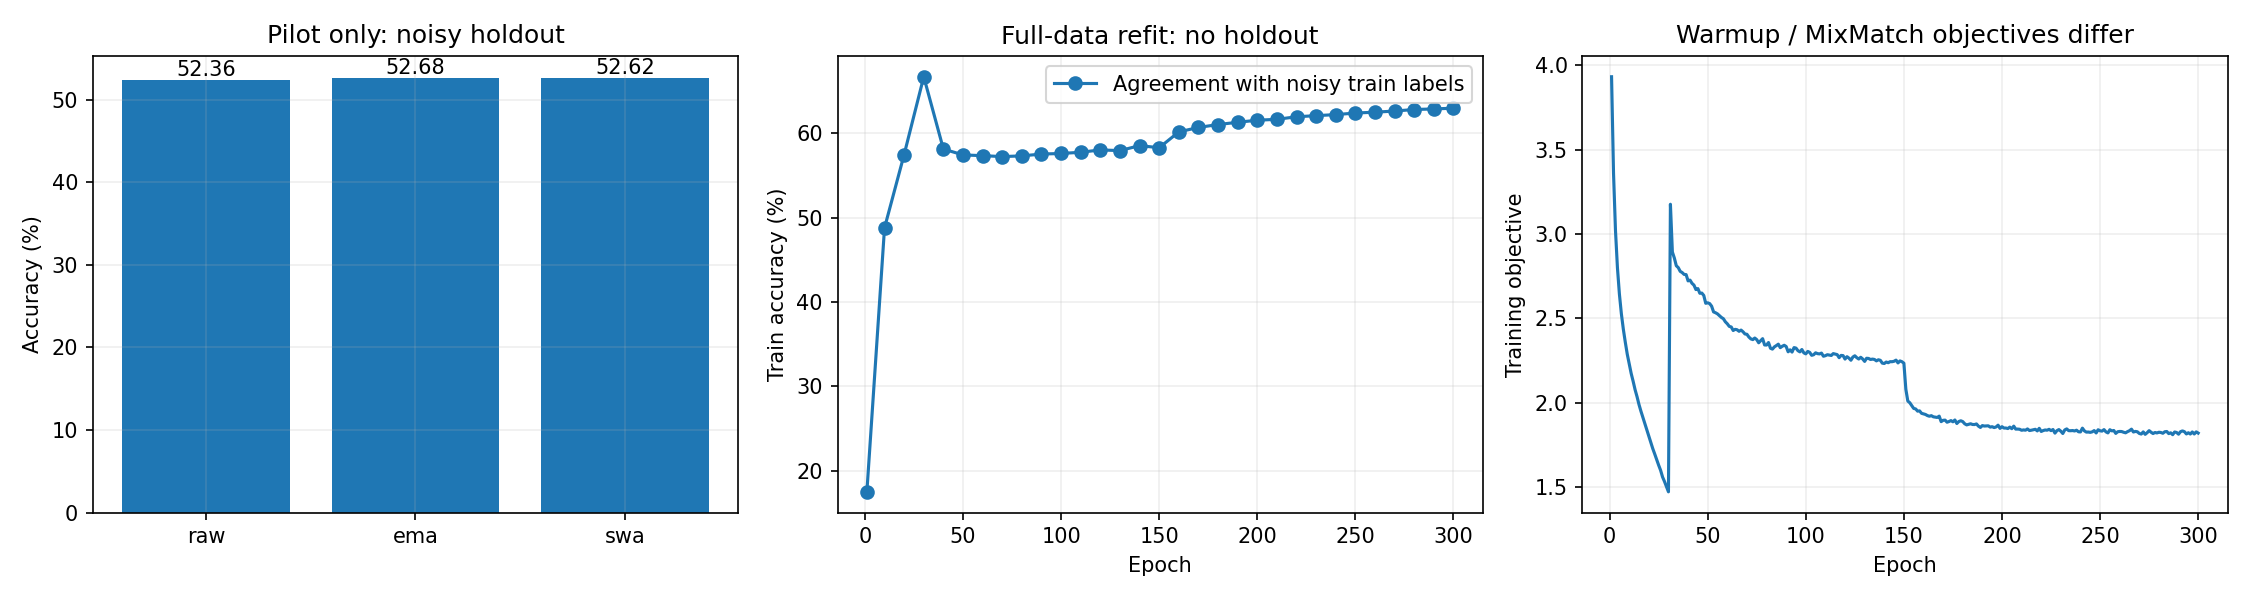

,epoch,epoch_complete,phase,train_accuracy,train_loss,val_accuracy,val_loss,objective_loss,network1_loss,network2_loss,...,amp_skipped_steps,network1_clean_count,network2_clean_count,network1_semi_supervised,network2_semi_supervised,lr,planned_epochs,samples_seen,train_metrics_seconds,seconds
295,296,True,peer_gmm_mixmatch,NaN,NaN,None,None,1.814697,1.813292,1.816103,...,0,31503,31455,True,True,0.002,300,62958,0.000006,91.708124
296,297,True,peer_gmm_mixmatch,NaN,NaN,None,None,1.827032,1.833757,1.820307,...,0,31464,31510,True,True,0.002,300,62974,0.000007,91.175211
297,298,True,peer_gmm_mixmatch,NaN,NaN,None,None,1.815079,1.802510,1.827649,...,0,31521,31517,True,True,0.002,300,63038,0.000007,91.762115
298,299,True,peer_gmm_mixmatch,NaN,NaN,None,None,1.827700,1.829034,1.826365,...,0,31505,31505,True,True,0.002,300,63010,0.000005,91.670324
299,300,True,peer_gmm_mixmatch,62.976,2.178556,None,None,1.820376,1.824221,1.816532,...,0,31572,31515,True,True,0.002,300,63087,10.666460,102.784570


In [19]:
display(Image(filename=str(plot_temporal_results(comparison, history, final_config))))
display(history.tail())
